# SETUP

In [25]:
# Libraries

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from statsmodels.tsa.seasonal import MSTL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy import stats
from statsmodels.tsa.arima.model import ARIMA

In [26]:
# loading data

CSV = Path("../data/raw/raw_data.csv")

df = pd.read_csv(CSV, parse_dates=["date"])
print(df.shape)
print(df.dtypes)
df.head()

(1053, 10)
row_id                         int64
date                  datetime64[ns]
complaints                   float64
is_weekend                     int64
bank_holiday_flag              int64
staffing_level_fte           float64
backlog_days                 float64
media_mentions                 int64
channel_mix_index            float64
centered_7d_mean             float64
dtype: object


,row_id,date,complaints,is_weekend,bank_holiday_flag,staffing_level_fte,backlog_days,media_mentions,channel_mix_index,centered_7d_mean
0,1,2023-01-01,75.0,1,1,36.4,13.4,1,54.4,80.50
1,2,2023-01-02,80.0,0,0,33.9,9.4,0,57.8,78.40
2,3,2023-01-03,84.0,0,0,34.7,11.2,2,54.9,76.33
3,4,2023-01-04,83.0,0,0,33.8,10.2,4,52.5,75.86
4,5,2023-01-05,70.0,0,0,NaN,11.5,1,47.7,76.14


# EDA

## Auditing Time Series: Dates Continuity

In [27]:
# auditing the time series: are there gaps in the calendar, and do they cluster?

print("Range:", df["date"].min().date(), "to", df["date"].max().date())
print("Sorted:", df["date"].is_monotonic_increasing)
print("Duplicate dates:", df["date"].duplicated().sum())

full = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
missing = pd.Series(full.difference(df["date"]))
print(f"Expected days: {len(full)} | present: {df['date'].nunique()} | missing: {len(missing)}")

# Consecutive missing days share a run id, so each row below is one gap
run_id = missing.diff().dt.days.ne(1).cumsum()
gaps = missing.groupby(run_id).agg(start="min", end="max", days="count")
gaps

Range: 2023-01-01 to 2025-12-31
Sorted: True
Duplicate dates: 0
Expected days: 1096 | present: 1053 | missing: 43


,start,end,days
1,2023-01-19,2023-01-19,1
2,2023-02-10,2023-02-10,1
3,2023-03-16,2023-03-16,1
4,2023-05-02,2023-05-02,1
5,2023-05-10,2023-05-10,1
6,2023-06-02,2023-06-02,1
7,2023-06-07,2023-06-07,1
8,2023-06-14,2023-06-14,1
9,2023-08-26,2023-08-26,1
10,2023-10-13,2023-10-13,1


Missing days: 43 of 1096 | longest gap: 2 days


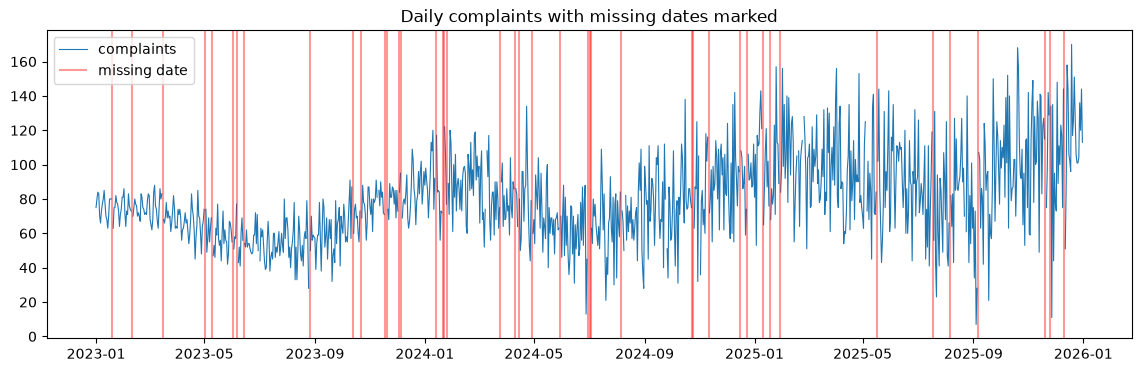

In [28]:
# 43 days missing: does it matter?

full = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
missing = pd.Series(full.difference(df["date"]))
longest = missing.diff().dt.days.ne(1).cumsum().value_counts().max()
print(f"Missing days: {len(missing)} of {len(full)} | longest gap: {longest} days")

daily = df.set_index("date")["complaints"].reindex(full)
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily.index, daily, lw=0.8, label="complaints")
# Red lines mark the missing dates, drawn full height so they're visible at any scale
ax.vlines(missing, 0, 1, transform=ax.get_xaxis_transform(), color="red", alpha=0.4, label="missing date")
ax.set_title("Daily complaints with missing dates marked")
ax.legend()
plt.show()

Checkpoint decision: missing dates. 43 of 1,096 days are missing, with no visible pattern, and no gap is longer than 2 days. The forecasting models need an unbroken daily calendar, so we reindex to every day and flag the added rows. These days will be filled for training only and never used to score models. Fill method decided after the next checks.

In [29]:
# reindex the dataframe to include the missing dates, and mark them with a boolean column
df = df.set_index("date").reindex(full)
df.index.name = "date"

# flag to identify the rows that were added by reindexing
df["missing_date"] = df["row_id"].isna()  # True for the 43 days added by reindexing

# checkpoint as new rows where added
print(df.shape)

# understanding missing data: before and after the reindexing 
added = df["missing_date"]
pd.DataFrame({
    "empty_total": df.isna().sum(),
    "from_added_days": df[added].isna().sum(),
    "in_original_rows": df[~added].isna().sum(),
})

(1096, 10)


,empty_total,from_added_days,in_original_rows
row_id,43,43,0
complaints,53,43,10
is_weekend,43,43,0
bank_holiday_flag,43,43,0
staffing_level_fte,74,43,31
backlog_days,64,43,21
media_mentions,43,43,0
channel_mix_index,64,43,21
centered_7d_mean,43,43,0
missing_date,0,0,0


## Checking Target Variable Behaviour

Range: 7 to 170 | mean 80.2 | median 77 | sd 25.4
Non-integers: 0 | negatives: 0 | zeros: 0


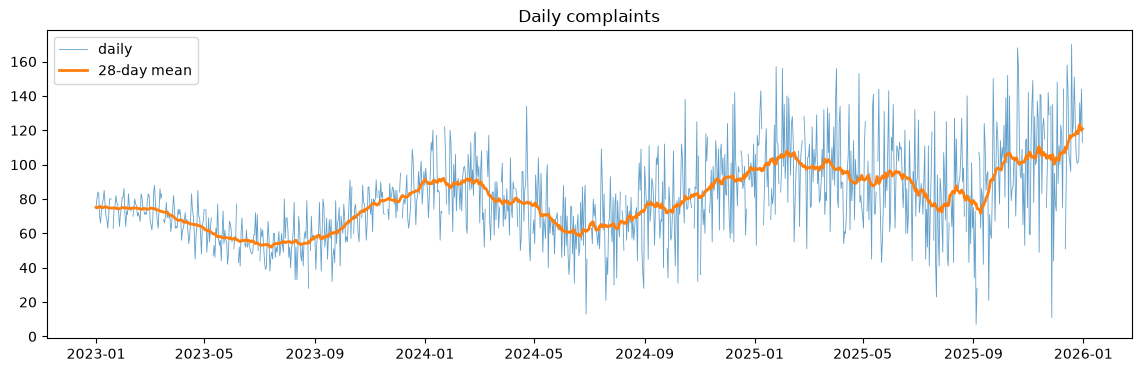

In [30]:
# checking target variable: complaints - behaviour expected: whole numbers, non-negative, and pausible range.

y = df["complaints"]
df["no_target"] = y.isna()  # the 53 days a model must never be scored on

obs = y.dropna()
print(f"Range: {obs.min():.0f} to {obs.max():.0f} | mean {obs.mean():.1f} | median {obs.median():.0f} | sd {obs.std():.1f}")

# A count should be whole and non-negative; anything else is a data error
print("Non-integers:", (obs % 1 != 0).sum(), "| negatives:", (obs < 0).sum(), "| zeros:", (obs == 0).sum())

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(y.index, y, lw=0.6, alpha=0.7, label="daily")
# 28 days = exactly 4 weeks, so the weekly cycle cancels out and the underlying level shows
ax.plot(y.index, y.rolling(28, center=True, min_periods=14).mean(), lw=2, label="28-day mean")
ax.set_title("Daily complaints")
ax.legend()
plt.show()

Checkpoint conclusion: Target var: Values are valid counts (7–170, no negatives or fractions). There is an overall uptrend, though not constant, with the series ending at its highest level. There is an apparent annual cycle with summer troughs and winter/spring peaks, so the forecast window (Jan–Mar) falls in the seasonal high. Day-to-day spread grows with the level, which suggests a log scale. Extreme low days look like single-day drops. Before treating them as outliers, we check whether they’re weekends or bank holidays.

## Checking accuracy of flags (raw file laballed them as approximate)

In [31]:
# flag is labelled "approximate", so compare it with the official list

# bank holidays from Gov.uk
EW_HOLIDAYS = pd.to_datetime([
    "2023-01-02", "2023-04-07", "2023-04-10", "2023-05-01", "2023-05-08", "2023-05-29", "2023-08-28", "2023-12-25", "2023-12-26",
    "2024-01-01", "2024-03-29", "2024-04-01", "2024-05-06", "2024-05-27", "2024-08-26", "2024-12-25", "2024-12-26",
    "2025-01-01", "2025-04-18", "2025-04-21", "2025-05-05", "2025-05-26", "2025-08-25", "2025-12-25", "2025-12-26",
    "2026-01-01",
])

orig = df[~df["missing_date"]]

# Weekend flag should follow directly from the date
true_weekend = (orig.index.dayofweek >= 5).astype(int)
print("is_weekend mismatches:", (orig["is_weekend"] != true_weekend).sum())

true_hol = orig.index.isin(EW_HOLIDAYS)
print("Flagged, not a real holiday:", orig.index[(orig["bank_holiday_flag"] == 1) & ~true_hol].date.tolist())
print("Real holiday, not flagged:", orig.index[(orig["bank_holiday_flag"] == 0) & true_hol].date.tolist())

is_weekend mismatches: 0
Flagged, not a real holiday: [datetime.date(2023, 1, 1)]
Real holiday, not flagged: [datetime.date(2023, 1, 2), datetime.date(2023, 5, 8)]


Checkpoint decision: calendar flags. is_weekend matches the calendar exactly. bank_holiday_flag differs from the official England & Wales list on 3 days, all in 2023: it marks 1 Jan instead of the substitute 2 Jan, and misses the Coronation (8 May). I rebuild both columns from the date. The official list replaces the approximate flag, the 43 added days get correct values instead of blanks, and the same list gives us holiday flags for the forecast window.

In [32]:
# Both columns are pure functions of the date, so rebuild them for every day, added ones included
df["is_weekend"] = (df.index.dayofweek >= 5).astype(int)
df["bank_holiday_flag"] = df.index.isin(EW_HOLIDAYS).astype(int)

print("Empty values left:", df[["is_weekend", "bank_holiday_flag"]].isna().sum().to_dict())
print("Bank holidays in data:", df["bank_holiday_flag"].sum())

Empty values left: {'is_weekend': 0, 'bank_holiday_flag': 0}
Bank holidays in data: 25


## Understanding Range of Target Variable (lows and changes)

In [33]:
# finding if low values follow a calendar pattern. Do they normally fall on Weekends, bank holidays, or no pattern at all?
low = df.nsmallest(20, "complaints")[["complaints", "is_weekend", "bank_holiday_flag"]]
low.assign(weekday=low.index.day_name())

,complaints,is_weekend,bank_holiday_flag,weekday
date,,,,
2025-09-04,7.0,0,0,Thursday
2025-11-27,11.0,0,0,Thursday
2024-06-28,13.0,0,0,Friday
2024-07-20,21.0,1,0,Saturday
2025-09-18,21.0,0,0,Thursday
2025-07-22,23.0,0,0,Tuesday
2023-08-25,28.0,0,0,Friday
2024-08-31,28.0,1,0,Saturday
2025-09-05,28.0,0,0,Friday


Checkpoint: The calendar doesn’t explain them, so we need a rule to identify extremes.

Robust scale of log residuals by quarter:
 date
2023Q1    0.032
2023Q2    0.067
2023Q3    0.101
2023Q4    0.090
2024Q1    0.144
2024Q2    0.176
2024Q3    0.190
2024Q4    0.159
2025Q1    0.128
2025Q2    0.241
2025Q3    0.264
2025Q4    0.176
Freq: Q-DEC, Name: complaints, dtype: float64

Flagged days: 8
            complaints     z    weekday
date                                   
2023-01-14        63.0  -6.7   Saturday
2023-07-29        80.0   5.1   Saturday
2023-08-25        28.0  -6.0     Friday
2023-09-20        32.0  -5.9  Wednesday
2024-06-28        13.0  -8.0     Friday
2024-07-20        21.0  -5.2   Saturday
2025-09-04         7.0 -13.0   Thursday
2025-11-27        11.0  -7.8   Thursday


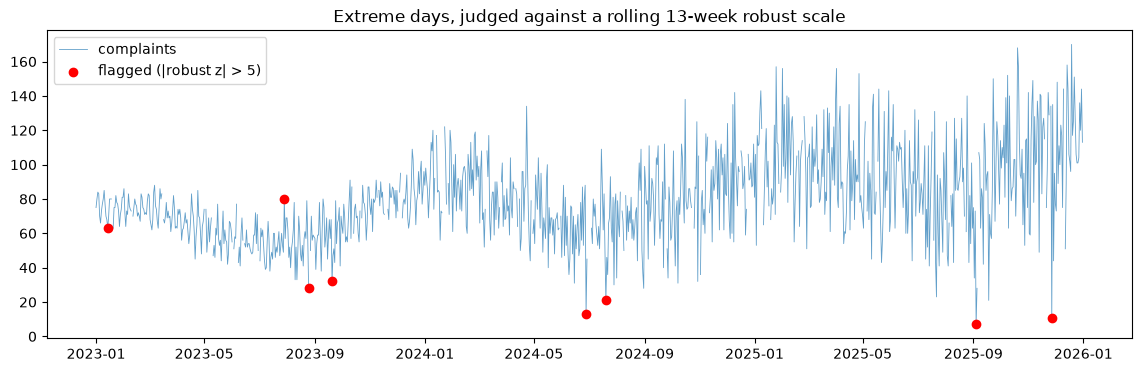

In [34]:
# Defining a "extreme day" by a rule: a robust z-score of each day's residual
# (vs the same weekday nearby), scaled by the local dispersion of residuals (rolling 13-week MAD)

# Log scale: deviations become proportional, so a drop of 20 weighs more at a level of 60 than at 120
logy = np.log(df["complaints"])

# Baseline (expected value): median of the same weekday over the surrounding 5 weeks.
# Being local, it removes trend and weekly seasonality, so the residual is "today vs a normal day like it"
baseline = logy.groupby(df.index.dayofweek).transform(lambda s: s.rolling(5, center=True, min_periods=3).median())
resid = logy - baseline

# Heteroscedasticity check: is the dispersion of residuals stable over time?
# Robust scale = MAD x 1.4826 (comparable to a standard deviation, but not pulled by the extremes themselves)
scale_by_quarter = resid.groupby(df.index.to_period("Q")).apply(lambda s: 1.4826 * (s - s.median()).abs().median())
print("Robust scale of log residuals by quarter:\n", scale_by_quarter.round(3))

# Dispersion grows over time, so one global scale would over-flag recent years.
# Use a rolling 13-week robust scale so each day is judged against the noise of its own period
w = 91
centre = resid.rolling(w, center=True, min_periods=w // 2).median()
scale = 1.4826 * (resid - centre).abs().rolling(w, center=True, min_periods=w // 2).median()
z = (resid - centre) / scale  # robust (modified) z-score

# |z| > 5: stricter than the usual 3.5 because tails are heavy; only days extreme even for their own period
df["anomaly"] = z.abs() > 5

print("\nFlagged days:", df["anomaly"].sum())
print(df.loc[df["anomaly"], ["complaints"]].assign(z=z.round(1), weekday=lambda d: d.index.day_name()))

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df.index, df["complaints"], lw=0.6, alpha=0.7, label="complaints")
ax.scatter(df.index[df["anomaly"]], df.loc[df["anomaly"], "complaints"], color="red", zorder=3, label="flagged (|robust z| > 5)")
ax.set_title("Extreme days, judged against a rolling 13-week robust scale")
ax.legend()
plt.show()

**Checkpoint decision: extreme days.**

| What we found | What we do about it |
|---|---|
| Day-to-day noise grows over time, much faster than the level (robust scale of log residuals by quarter: 0.03 in early 2023 to 0.26 in mid-2025, printed above). The series is heteroscedastic. | Judge each day against the noise of its own period (rolling 13-week robust scale), not one scale for the whole series, which would over-flag the noisier recent years. |
| Noise drifts within years too, not just between them. | No yearly cut-off: a calendar boundary would be arbitrary and would over-flag calm 2023. |
| 8 days are extreme even for their own period (7 low, 1 high; absolute robust z above 5). | Treat them as missing for training, filled with the same-weekday local median, so the model doesn't learn one-off drops as pattern. Keep their actual values for scoring: we only exclude days where the truth is unknown. |
| Recent noise is much higher than the 3-year average, and early 2023 is a calmer regime. | Carried to modelling: prediction intervals are checked on recent backtest windows. If coverage falls short, we test training from 2024 onwards. |

## Filling missing data to complete dataset

In [35]:
# Training needs a value for every day: fill days with no recorded target (missing dates + empty values)
# and days flagged as extreme, so the model doesn't learn one-off drops as pattern
to_fill = df["complaints"].isna() | df["anomaly"]

# Fill with the local baseline: median of the same weekday over the surrounding 5 weeks (keeps weekly rhythm and local level)
df["complaints_clean"] = df["complaints"].where(~to_fill, np.exp(baseline).round())

print("Days filled:", to_fill.sum(), "| empty left:", df["complaints_clean"].isna().sum())

Days filled: 61 | empty left: 0


Checkpoint decision: fill method. Days without a recorded target and days flagged as extreme are filled with the median of the same weekday over the surrounding 5 weeks. This respects weekly seasonality and the local level, unlike linear interpolation, which would blend weekdays and weekends. The original column is kept for scoring, so filled values are never used to evaluate a model.

## Time Series Diagnostic: Standard checks to characterise the series and decide what a model must handle

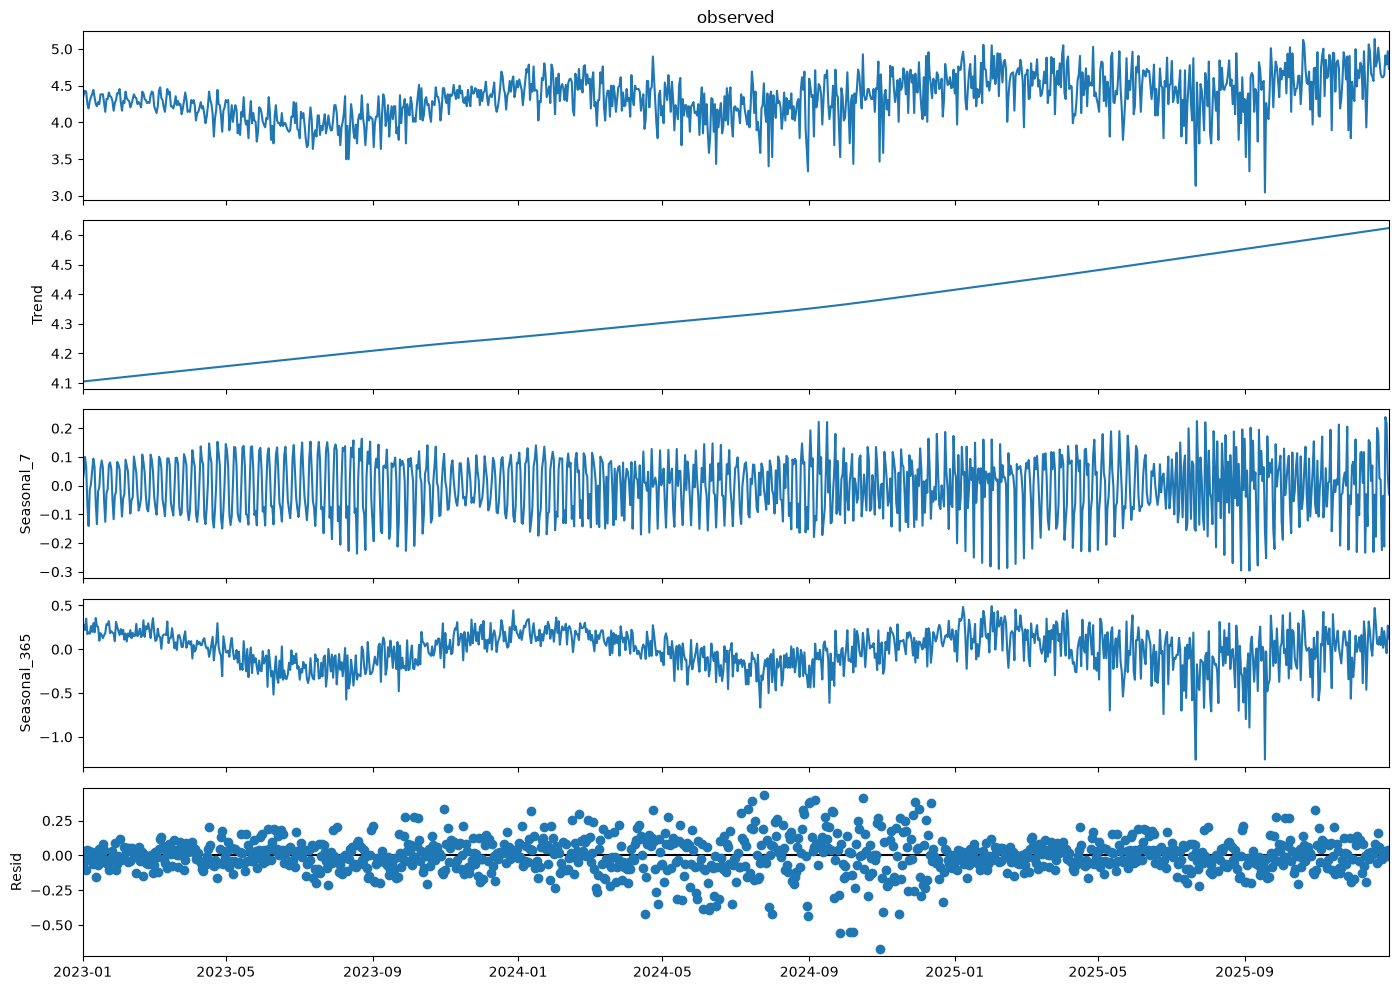

Trend strength:   0.57
Weekly strength:  0.4
Annual strength:  0.76
seasonal_7: peak is 1.71x the trough
seasonal_365: peak is 5.76x the trough


In [36]:
# Log scale so seasonal effects are proportional (a Monday is "x% above average", not "+n complaints")
log_clean = np.log(df["complaints_clean"])

# MSTL handles several seasonal periods at once: weekly (7) and annual (365)
mstl = MSTL(log_clean, periods=(7, 365)).fit()
fig = mstl.plot()
fig.set_size_inches(14, 10)  # wide enough to read three years of daily data
fig.tight_layout()
plt.show()

# Strength of each component (Hyndman's measure): share of variation it explains beyond the remainder, 0 to 1
R = mstl.resid
def strength(component):
    return max(0, 1 - R.var() / (component + R).var())

print("Trend strength:  ", round(strength(mstl.trend), 2))
print("Weekly strength: ", round(strength(mstl.seasonal["seasonal_7"]), 2))
print("Annual strength: ", round(strength(mstl.seasonal["seasonal_365"]), 2))

# Peak-to-trough size of each seasonal pattern, as a ratio (log differences convert to multiplicative effects)
for col in ["seasonal_7", "seasonal_365"]:
    s = mstl.seasonal[col]
    print(f"{col}: peak is {np.exp(s.max() - s.min()):.2f}x the trough")

ADF p = 0.266 (small → reject non-stationary) | KPSS p = 0.021 (small → reject stationary)


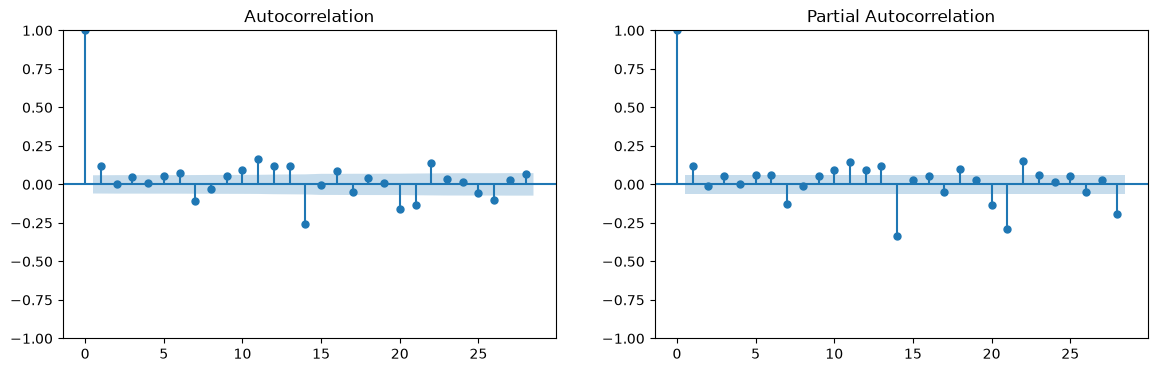

In [37]:
# Complementary tests: ADF's null is "non-stationary", KPSS's null is "stationary".
# 'ct' tests stationarity around a trend; agreement between the two is what makes the conclusion convincing
adf_p = adfuller(log_clean, regression="ct", autolag="AIC", result_object=False)[1]
kpss_p = kpss(log_clean, regression="ct", nlags="auto", result_object=False)[1]  # KPSS p-values are capped at 0.01–0.10 by its look-up table
print(f"ADF p = {adf_p:.3f} (small → reject non-stationary) | KPSS p = {kpss_p:.3f} (small → reject stationary)")

# Leftover autocorrelation after trend + seasonality: if present, the model needs ARIMA errors
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(mstl.resid, lags=28, ax=axes[0])
plot_pacf(mstl.resid, lags=28, ax=axes[1], method="ywm")
plt.show()

In [38]:
# Numbers quoted in the EDA conclusion, computed here so every claim can be checked
year = df.index.year

trend = np.exp(mstl.trend)
print(f"Trend level: {trend.iloc[0]:.0f} → {trend.iloc[-1]:.0f}")
print("Trend growth by year, % (mean level):", (trend.groupby(year).mean().pct_change() * 100).round(0).dropna().to_dict())

mad = lambda s: 1.4826 * (s - s.median()).abs().median()
print("Robust sd of log residuals by year:", resid.groupby(year).apply(mad).round(3).to_dict())
print("Mean complaints by year:", df["complaints"].groupby(year).mean().round(0).to_dict())

wk = mstl.seasonal["seasonal_7"]
print("Weekly peak-to-trough by year:", wk.groupby(year).apply(lambda s: np.exp(s.max() - s.min())).round(2).to_dict())

# Smoothing over 28 days strips the single-day noise the raw annual component absorbed
annual = mstl.seasonal["seasonal_365"].rolling(28, center=True).mean()
print(f"Annual peak-to-trough, 28-day smoothed: {np.exp(annual.max() - annual.min()):.2f}x")

d = log_clean.diff().dropna()
adf_d = adfuller(d, regression="c", autolag="AIC", result_object=False)[1]
kpss_d = kpss(d, regression="c", nlags="auto", result_object=False)[1]
print(f"After one difference: ADF p = {adf_d:.3f} | KPSS p = {kpss_d:.3f}")

Trend level: 61 → 102
Trend growth by year, % (mean level): {2024: 16.0, 2025: 21.0}
Robust sd of log residuals by year: {2023: 0.056, 2024: 0.161, 2025: 0.196}
Mean complaints by year: {2023: 67.0, 2024: 78.0, 2025: 96.0}
Weekly peak-to-trough by year: {2023: 1.49, 2024: 1.49, 2025: 1.71}
Annual peak-to-trough, 28-day smoothed: 1.66x
After one difference: ADF p = 0.000 | KPSS p = 0.100


/tmp/ipykernel_64696/3503824212.py:21: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_d = kpss(d, regression="c", nlags="auto", result_object=False)[1]


# FEATURE SELECTION

centered_7d_mean: excluded on availability. A centred 7-day mean on day t averages complaints from t−3 to t+3. On every forecast day it depends on future complaints, which is the quantity we're forecasting, so it can never be known at forecast time. Used as a feature, it would also leak the target into training and make backtests look far better than any real forecast could be. The exclusion doesn't depend on the exact window: any rolling mean of complaints is unknown across a 90-day horizon.

In [39]:
# Testing the rest of the features for correlation with complaints

ops = ["staffing_level_fte", "backlog_days", "media_mentions", "channel_mix_index"]

# Change vs the same weekday last week: removes shared trend and weekly seasonality,
# so any remaining correlation reflects real co-movement, not both series drifting upwards
y_w = np.log(df["complaints_clean"]).diff(7)

rows = []
for col in ops:
    x_w = df[col].diff(7)
    # shift(k) pairs today's complaints with the feature k days earlier:
    # k > 0 → feature moves first (could predict); k < 0 → feature follows complaints (consequence, not cause)
    lags = {k: y_w.corr(x_w.shift(k)) for k in range(-7, 8)}
    best = max(lags, key=lambda k: abs(lags[k]))
    rows.append({
        "feature": col,
        "raw_corr": df["complaints"].corr(df[col]),
        "weekly_change_corr": y_w.corr(x_w),
        "strongest_lag": best,
        "corr_at_lag": lags[best],
    })
pd.DataFrame(rows).round(2)

,feature,raw_corr,weekly_change_corr,strongest_lag,corr_at_lag
0,staffing_level_fte,0.39,-0.04,-3,-0.09
1,backlog_days,0.28,-0.24,-7,0.48
2,media_mentions,-0.04,0.01,-6,0.07
3,channel_mix_index,0.01,0.00,4,-0.04


**Checkpoint decision: operational features.** All four are excluded.

- **Availability:** none is known for Jan–Mar 2026, so using one would mean forecasting it first and carrying that error into the complaints forecast.
- **Evidence** (week-on-week changes, which remove shared trend and weekly seasonality; lags −7 to +7 days):
  - Staffing's raw correlation (0.39) disappears (−0.04), so it was shared trend.
  - Backlog moves 7 days *after* complaints (0.48 at lag −7). It's a consequence of complaint volume, not a driver.
  - Media mentions and channel mix show no relationship at any tested lag.

No feature leads complaints, so there's no case for including any of them, even if their future values were known.

In [40]:
# Compare each day with a normal same weekday nearby (the baseline from the extreme-days section)
ratio = df["complaints"] / np.exp(baseline)
weekday = df.index.dayofweek

print("Bank holidays run at", round(ratio[df["bank_holiday_flag"] == 1].median(), 2), "x a normal same weekday")
print("Median complaints by weekday:\n", df.groupby(weekday)["complaints"].median().rename(index=dict(enumerate(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]))))

Bank holidays run at 1.0 x a normal same weekday
Median complaints by weekday:
 date
Mon    84.0
Tue    81.0
Wed    80.5
Thu    71.0
Fri    70.0
Sat    73.0
Sun    75.5
Name: complaints, dtype: float64


**Checkpoint decision: calendar features.**

- **Day-of-week: kept.** Complaints follow a weekly gradient (median Mon 84 → Thu/Fri 70–71, weekend 73–76), not a weekday/weekend split. The model uses one effect per weekday.
- **is_weekend: dropped.** It's fully contained in day-of-week, and it misrepresents the pattern (weekends aren't the low point).
- **bank_holiday_flag: dropped.** Holidays run at 1.0x a normal same weekday, so there's no measurable effect. The flag was still worth correcting, because that's what made this test trustworthy.

## EDA conclusion

**Findings**

- **Trend:** rising and accelerating (trend level about 61 → 102 over three years; +16% in 2024, +21% in 2025).
- **Stationarity:** ADF (p = 0.27) and KPSS (p = 0.02) agree that the log series is not stationary around a straight-line trend. After one difference, both tests indicate stationarity.
- **Weekly seasonality:** moderate (strength 0.40) and strengthening (peak-to-trough 1.49x in 2023–24, 1.71x in 2025). It is a gradient across the week (Mondays highest, Thursdays and Fridays lowest), not a weekday/weekend split.
- **Annual seasonality:** present, at about 1.7x peak-to-trough once smoothed, with summer troughs and winter/spring peaks. The raw MSTL component (5.76x) absorbs single-day noise, since three years provide only three cycles. **The forecast window (Jan–Mar) falls in the seasonal high.**
- **Dispersion:** grows faster than the level. The robust sd of log residuals went 0.056 (2023) → 0.161 (2024) → 0.196 (2025), while the mean rose 67 → 78 → 96. The log scale alone does not stabilise it.
- **Leftover dependence:** after trend and seasonality are removed, only mild lag-1 autocorrelation and some weekly structure remain. The remainder is mostly noise.

**Model requirements**

| Finding | Requirement |
|---|---|
| Trend + non-stationarity | One difference with drift (constant % growth on the log scale). This does not extrapolate the acceleration, so it may under-forecast if growth keeps speeding up. |
| Growth and seasonality are proportional | Log scale |
| Weekly gradient | One effect per weekday |
| Annual cycle, only three cycles observed | A smooth annual shape (low-order Fourier terms) rather than a free day-of-year effect |
| Mild short-term dependence | Short ARIMA error terms |
| Growing dispersion, strengthening weekly pattern | Not built into the model. Checked in the backtest through 80/95% interval coverage on recent windows. |

Not required: bank holidays (no effect found, 1.0x a normal same weekday across 25 holidays) and the operational columns (see feature validation).

**Shortlist**

- **Seasonal naive (weekly):** baseline, and the reference for MASE.
- **Dynamic harmonic regression (log scale):** Fourier annual terms, weekday dummies, and ARIMA(p,1,q) errors with drift. It represents the trend, both seasonal cycles and the short-term dependence directly, and its coefficients can be explained in plain language. Limitation: fixed weekday effects and constant variance, so the backtest coverage decides whether its intervals hold up.
- **DHR without annual terms (ablation):** the same model with the Fourier terms removed. It tests whether the annual cycle earns its place, with only one thing changed.

Considered, not shortlisted: AutoGluon's ETS, ARIMA and Theta take a single seasonal period, so they cannot represent both cycles. Its tabular forecasters would need engineered annual features and differencing to follow the trend. Both would be workarounds for what DHR represents directly.

**Bonus (separate section):** Chronos-Bolt zero-shot, to test whether a pretrained foundation model beats the purpose-built model on this series.

# MODELLING

## Backtest design

The rules every model is judged by, fixed before any model is fitted so they can't be tuned to favour one.

- **Windows:** 4 back-to-back 90-day windows covering 2025 (W1 6 Jan–5 Apr, W2 6 Apr–4 Jul, W3 5 Jul–2 Oct, W4 3 Oct–31 Dec). Each model forecasts each window using only the data before it, exactly as it will forecast 2026. W1 covers the same season as the real forecast.
- **Cleaning per window:** missing and extreme days are filled using only that window's training data. The exploratory cleaning used centred windows across the full series, which near a cutoff would see test values.
- **Scoring:** on recorded values only. Filled days and days with no recorded target are never scored.
- **Metrics:**
  - **MAE:** average daily error, in complaints.
  - **MASE:** MAE divided by seasonal naive's in-sample one-week-ahead error. Comparable across windows at different levels.
  - **Weekly total error (%):** absolute % error of weekly totals, on complete calendar weeks only. This is the unit capacity planning uses.
  - **Bias (%):** forecast total minus actual total over the window. Shows systematic under- or over-forecasting (the drift risk noted in the EDA).
  - **80% / 95% coverage:** share of days inside each interval. Should be close to 0.80 and 0.95.
- **Selection rule:** the primary metric is MASE averaged over the 4 windows. A model must beat seasonal naive on average MASE and in at least 3 of 4 windows. Between models within 0.02 MASE of each other, the simpler one wins. If 95% coverage falls below 0.90, the intervals are too narrow, and we test training from 2024 onwards (see extreme days).
- **Limitation:** 4 windows, all in one year, is a small sample. Differences of a few hundredths in MASE are not meaningful.

In [41]:
def clean_target(y):
    """Fill missing and extreme days using only the data passed in, so it never sees past its last date.
    Same rules as the exploration: same-weekday baseline, rolling 13-week robust scale, |z| > 5."""
    logy = np.log(y)
    baseline = logy.groupby(logy.index.dayofweek).transform(lambda s: s.rolling(5, center=True, min_periods=3).median())
    resid = logy - baseline
    w = 91
    centre = resid.rolling(w, center=True, min_periods=w // 2).median()
    scale = 1.4826 * (resid - centre).abs().rolling(w, center=True, min_periods=w // 2).median()
    extreme = ((resid - centre) / scale).abs() > 5
    to_fill = y.isna() | extreme
    return y.where(~to_fill, np.exp(baseline).round()), to_fill


def score(actual, fc, train):
    a = actual.dropna()  # score only days with a recorded target
    f = fc.loc[a.index, :]
    err = a - f["mean"]
    # Complete calendar weeks only: windows start mid-week, and a 1–3 day stub isn't a weekly total
    days = pd.Series(1, index=actual.index).resample("W").sum()
    weekly = pd.DataFrame({"a": a, "f": f["mean"]}).resample("W").sum().loc[days[days == 7].index]
    return {
        "MAE": err.abs().mean(),
        "MASE": err.abs().mean() / (train - train.shift(7)).abs().mean(),
        "weekly_APE_%": 100 * ((weekly["a"] - weekly["f"]).abs() / weekly["a"]).mean(),
        "bias_%": 100 * (f["mean"].sum() - a.sum()) / a.sum(),
        "cover_80": ((a >= f["lo80"]) & (a <= f["hi80"])).mean(),
        "cover_95": ((a >= f["lo95"]) & (a <= f["hi95"])).mean(),
        "width_80_%": 100 * (f["hi80"] - f["lo80"]).mean() / a.mean(),
    }


def backtest(forecast_fn, name):
    """forecast_fn(train, h) returns a DataFrame indexed by the h forecast dates, with mean, lo80, hi80, lo95, hi95."""
    rows = []
    for i, (start, end) in enumerate(windows, 1):
        train, _ = clean_target(df.loc[:start - pd.Timedelta(days=1), "complaints"])
        assert train.notna().all(), f"W{i}: training data still has empty days after cleaning"
        fc = forecast_fn(train, H)
        rows.append({"model": name, "window": f"W{i} {start:%b %Y}", **score(df.loc[start:end, "complaints"], fc, train)})
    return pd.DataFrame(rows)


H = 90
END = df.index.max()
windows = [(END - pd.Timedelta(days=H * k - 1), END - pd.Timedelta(days=H * (k - 1))) for k in range(4, 0, -1)]

pd.DataFrame(windows, columns=["start", "end"]).assign(
    days=lambda w: (w["end"] - w["start"]).dt.days + 1,
    starts_on=lambda w: w["start"].dt.day_name(),
    scored_days=[df.loc[s:e, "complaints"].notna().sum() for s, e in windows],
)

,start,end,days,starts_on,scored_days
0,2025-01-06,2025-04-05,90,Monday,85
1,2025-04-06,2025-07-04,90,Sunday,88
2,2025-07-05,2025-10-02,90,Saturday,86
3,2025-10-03,2025-12-31,90,Friday,87


In [42]:
def seasonal_naive(train, h):
    """Repeat the last observed week; standard seasonal-naive intervals (sd grows with each extra week ahead)."""
    idx = pd.date_range(train.index[-1] + pd.Timedelta(days=1), periods=h, freq="D")
    mean = np.resize(train.iloc[-7:].to_numpy(), h)
    sigma = (train - train.shift(7)).std()
    sd = sigma * np.sqrt(np.arange(h) // 7 + 1)
    out = pd.DataFrame({"mean": mean}, index=idx)
    for lvl in (80, 95):
        zq = stats.norm.ppf(0.5 + lvl / 200)
        out[f"lo{lvl}"], out[f"hi{lvl}"] = mean - zq * sd, mean + zq * sd
    return out


sn = backtest(seasonal_naive, "Seasonal naive")
results = [sn]
display(sn.round(2))
sn.mean(numeric_only=True).round(2)

,model,window,MAE,MASE,weekly_APE_%,bias_%,cover_80,cover_95,width_80_%
0,Seasonal naive,W1 Jan 2025,22.59,1.62,5.55,-6.56,0.96,0.98,125.08
1,Seasonal naive,W2 Apr 2025,33.20,2.19,24.88,22.47,0.83,0.97,149.78
2,Seasonal naive,W3 Jul 2025,28.40,1.71,23.94,15.44,0.92,0.99,185.29
3,Seasonal naive,W4 Oct 2025,26.61,1.52,9.16,-3.25,0.94,0.98,144.82


MAE              27.70
MASE              1.76
weekly_APE_%     15.88
bias_%            7.02
cover_80          0.91
cover_95          0.98
width_80_%      151.24
dtype: float64

**Checkpoint: seasonal naive baseline.** Mean MASE 1.76 (1.52–2.19 across windows). This is the bar every model must clear.

- **Bias shows the annual cycle and trend at work.** Repeating the last week can't anticipate seasonal swings or growth: W1 under-forecasts the rise into the winter high (−6.6%), W2 and W3 over-forecast the drop into the summer trough (+22%, +15%), and W4 roughly balances (−3%). Weekly total error follows the same pattern (6–9% in W1 and W4, about 24% in W2 and W3).
- **Intervals are safe but too wide to plan with.** Coverage is high (80%: 0.91 on average; 95%: 0.98), but the 80% band averages 151% of mean daily complaints. The seasonal-naive formula widens every week ahead, so by week 13 the band is about 3.6 times its first-week width.

## Model: Dynamic harmonic regression

Regression on log complaints with a linear time trend (constant % growth), weekday effects (Monday as reference) and K sin/cos pairs for the annual cycle, with AR(1) errors. Fitted with statsmodels `ARIMA`, which treats the regressors as a regression with ARIMA errors. The order is fixed rather than searched, since searching on one series overfits. Forecasts are back-transformed with exp, so the point forecast is the median of the forecast distribution, not the mean.

In [43]:
EPOCH = pd.Timestamp("2000-01-01")  # fixed origin, so annual terms line up between training and forecast dates

def calendar_features(dates, K):
    """Weekday dummies (Monday as reference) plus K sin/cos pairs for the annual cycle."""
    X = pd.DataFrame({f"dow_{d}": (dates.dayofweek == d).astype(float) for d in range(1, 7)}, index=dates)
    t = (dates - EPOCH).days.to_numpy()
    for k in range(1, K + 1):
        X[f"sin{k}"] = np.sin(2 * np.pi * k * t / 365.25)
        X[f"cos{k}"] = np.cos(2 * np.pi * k * t / 365.25)
    return X


def make_dhr(K, order=(1, 0, 0), trend="ct", recent_days=None):
    """Return a forecast_fn for the backtest: DHR on log complaints with K annual Fourier pairs.
    recent_days: if set, rescale the intervals to the residual spread of the last recent_days."""
    def dhr(train, h):
        future = pd.date_range(train.index[-1] + pd.Timedelta(days=1), periods=h, freq="D")
        res = ARIMA(np.log(train), exog=calendar_features(train.index, K), order=order, trend=trend).fit(method="innovations_mle")
        fc = res.get_forecast(steps=h, exog=calendar_features(future, K))
        log_mean = fc.predicted_mean.to_numpy()
        # Noise has grown over time, so one full-history variance understates the recent period
        k = res.resid.iloc[-recent_days:].std() / np.sqrt(res.params["sigma2"]) if recent_days else 1.0
        out = pd.DataFrame({"mean": np.exp(log_mean)}, index=future)
        for lvl in (80, 95):
            half = fc.conf_int(alpha=1 - lvl / 100).to_numpy()[:, 1] - log_mean
            out[f"lo{lvl}"], out[f"hi{lvl}"] = np.exp(log_mean - k * half), np.exp(log_mean + k * half)
        return out
    return dhr


# Sanity check on the full history: do the coefficients agree with the EDA?
y_all, _ = clean_target(df["complaints"])
res = ARIMA(np.log(y_all), exog=calendar_features(y_all.index, 2), order=(1, 0, 0), trend="ct").fit(method="innovations_mle")
p = res.params

# Trend terms come first in statsmodels' parameter list (constant, then time trend); printing names confirms it
print("Trend terms:", p.index[:2].tolist())
print(f"Growth = {100 * (np.exp(p.iloc[1] * 365.25) - 1):.1f}% a year")
print("Weekday effect vs Monday, %:", (100 * (np.exp(p.filter(like="dow_")) - 1)).round(1).to_dict())

year_dates = pd.date_range("2025-01-01", "2025-12-31", freq="D")
F = calendar_features(year_dates, 2).filter(regex="sin|cos")
annual = F @ p[F.columns]
print(f"Annual peak-to-trough: {np.exp(annual.max() - annual.min()):.2f}x | peak {annual.idxmax():%d %b} | trough {annual.idxmin():%d %b}")
print("ARIMA terms:", p.filter(like=".L").round(2).to_dict(), "| sigma2:", round(p["sigma2"], 4))

Trend terms: ['const', 'drift']
Growth = 18.0% a year
Weekday effect vs Monday, %: {'dow_1': -1.8, 'dow_2': -1.2, 'dow_3': -13.6, 'dow_4': -16.3, 'dow_5': -12.7, 'dow_6': -4.9}
Annual peak-to-trough: 1.48x | peak 28 Jan | trough 24 Jul
ARIMA terms: {'ar.L1': -0.01} | sigma2: 0.0564


**Checkpoint: DHR sanity fit.** The first specification, ARIMA(1,1,1) errors with drift, gave an MA coefficient of −0.99 and failed to converge. That is the classic sign of over-differencing: once weekday and annual terms are in the model, the trend behaves as a steady deterministic line, not a random walk. Refitted with a linear trend and AR(1) errors, it converges with almost identical estimates, and they agree with the EDA:

- **Growth:** 18% a year (EDA: +16% in 2024, +21% in 2025).
- **Weekly gradient:** Thursday to Saturday run 13–16% below Monday; Tuesday and Wednesday about 1–2% below.
- **Annual cycle:** 1.48x peak-to-trough, peaking in late January and bottoming in late July. The forecast window starts at the seasonal peak.
- **Short-term dependence:** AR(1) ≈ 0, so almost none remains.

What to watch in the backtest: with a deterministic trend and one variance estimated over the full history, the intervals scale with the level but don't widen with the horizon or reflect the noisier recent period. Coverage will show whether they are too narrow.

In [44]:
dhr2 = backtest(make_dhr(K=2), "DHR (K=2)")
dhr0 = backtest(make_dhr(K=0), "DHR, no annual terms")
results = [sn, dhr2, dhr0]  # rebuilt each run, so rerunning never duplicates rows

comparison = pd.concat(results)
display(comparison.round(2))
comparison.groupby("model", sort=False).mean(numeric_only=True).round(2)

,model,window,MAE,MASE,weekly_APE_%,bias_%,cover_80,cover_95,width_80_%
0,Seasonal naive,W1 Jan 2025,22.59,1.62,5.55,-6.56,0.96,0.98,125.08
1,Seasonal naive,W2 Apr 2025,33.20,2.19,24.88,22.47,0.83,0.97,149.78
2,Seasonal naive,W3 Jul 2025,28.40,1.71,23.94,15.44,0.92,0.99,185.29
3,Seasonal naive,W4 Oct 2025,26.61,1.52,9.16,-3.25,0.94,0.98,144.82
0,DHR (K=2),W1 Jan 2025,19.05,1.37,5.06,-4.70,0.68,0.88,47.59
1,DHR (K=2),W2 Apr 2025,22.53,1.48,16.04,-13.94,0.56,0.75,44.14
2,DHR (K=2),W3 Jul 2025,23.25,1.40,16.25,-1.58,0.56,0.71,53.43
3,DHR (K=2),W4 Oct 2025,24.42,1.39,8.77,-3.58,0.70,0.84,57.90
0,"DHR, no annual terms",W1 Jan 2025,25.34,1.82,21.09,-21.74,0.60,0.87,49.47
1,"DHR, no annual terms",W2 Apr 2025,19.57,1.29,8.95,-0.78,0.81,0.94,64.32


,MAE,MASE,weekly_APE_%,bias_%,cover_80,cover_95,width_80_%
model,,,,,,,
Seasonal naive,27.70,1.76,15.88,7.02,0.91,0.98,151.24
DHR (K=2),22.31,1.41,11.53,-5.95,0.62,0.80,50.76
"DHR, no annual terms",24.54,1.56,17.13,-5.65,0.67,0.88,62.26


In [45]:
dhr2r = backtest(make_dhr(K=2, recent_days=365), "DHR (K=2), recent-spread intervals")
results = [sn, dhr2, dhr0, dhr2r]
comparison = pd.concat(results)

display(dhr2r.round(2))
display(comparison.groupby("model", sort=False).mean(numeric_only=True).round(2))
# The widening factor the final 2026 forecast would get (res = the full-history fit from the sanity check)
print(f"Widening factor on full history: {res.resid.iloc[-365:].std() / np.sqrt(res.params['sigma2']):.2f}")

,model,window,MAE,MASE,weekly_APE_%,bias_%,cover_80,cover_95,width_80_%
0,"DHR (K=2), recent-spread intervals",W1 Jan 2025,19.05,1.37,5.06,-4.70,0.82,0.94,61.45
1,"DHR (K=2), recent-spread intervals",W2 Apr 2025,22.53,1.48,16.04,-13.94,0.70,0.88,58.13
2,"DHR (K=2), recent-spread intervals",W3 Jul 2025,23.25,1.40,16.25,-1.58,0.69,0.86,70.08
3,"DHR (K=2), recent-spread intervals",W4 Oct 2025,24.42,1.39,8.77,-3.58,0.78,0.92,76.33


,MAE,MASE,weekly_APE_%,bias_%,cover_80,cover_95,width_80_%
model,,,,,,,
Seasonal naive,27.70,1.76,15.88,7.02,0.91,0.98,151.24
DHR (K=2),22.31,1.41,11.53,-5.95,0.62,0.80,50.76
"DHR, no annual terms",24.54,1.56,17.13,-5.65,0.67,0.88,62.26
"DHR (K=2), recent-spread intervals",22.31,1.41,11.53,-5.95,0.75,0.90,66.50


Widening factor on full history: 1.29


**Checkpoint decision: model selection.** DHR (K = 2) with recent-spread intervals is the final model.

- **Accuracy:** mean MASE 1.41 against seasonal naive's 1.76, better in all 4 windows. Weekly total error 11.5% against 15.9%.
- **The annual cycle earns its place:** removing the Fourier terms worsens MASE to 1.56 and loses 3 of 4 windows. The biggest gain is in W1, the same season as the real forecast (weekly error 5% vs 21%, bias −5% vs −22%).
- **Intervals:** with one full-history variance they were too narrow (95% coverage 0.80). The rule fixed in advance was to retrain from 2024, but for W1 that leaves one annual cycle, too little to separate the annual shape from the trend. Instead the intervals are rescaled by the residual spread of the last 365 days (one full year, so every season counts equally). Point forecasts are unchanged; 95% coverage rises to 0.90 (0.94 in W1), and the 80% band is less than half as wide as seasonal naive's.
- **Known limitations:** the model under-forecasts by about 6% on average (constant growth doesn't capture the acceleration seen in 2025), and intervals still under-cover in summer (W3) and when the forecast is biased (W2). W1, the season we're forecasting, is the best-behaved window.

In [46]:
   print(comparison.groupby("model", sort=False).mean(numeric_only=True).round(2).to_string())
   print(f"Widening factor on full history: {res.resid.iloc[-365:].std() / np.sqrt(res.params['sigma2']):.2f}")

                                      MAE  MASE  weekly_APE_%  bias_%  cover_80  cover_95  width_80_%
model                                                                                                
Seasonal naive                      27.70  1.76         15.88    7.02      0.91      0.98      151.24
DHR (K=2)                           22.31  1.41         11.53   -5.95      0.62      0.80       50.76
DHR, no annual terms                24.54  1.56         17.13   -5.65      0.67      0.88       62.26
DHR (K=2), recent-spread intervals  22.31  1.41         11.53   -5.95      0.75      0.90       66.50
Widening factor on full history: 1.29


The model is fitted with `method="innovations_mle"` (regression coefficients by GLS, AR term by maximum likelihood), because the default optimiser failed to converge on some backtest windows.

# FINAL FORECAST

DHR (K = 2) with recent-spread intervals, refitted on the full cleaned history (2023–2025) and forecasting 1 Jan – 31 Mar 2026. Outputs go to `outputs/`: the daily forecast with 80% and 95% intervals, weekly totals for capacity planning, and a plot.

Mean daily forecast 118 vs Jan–Mar 2025 actual 101 (+17%)
               total  days
week_starting             
2025-12-29       445     4
2026-01-05       829     7
2026-01-12       835     7
2026-01-19       840     7
2026-01-26       845     7
2026-02-02       846     7
2026-02-09       844     7
2026-02-16       841     7
2026-02-23       836     7
2026-03-02       829     7
2026-03-09       819     7
2026-03-16       809     7
2026-03-23       796     7
2026-03-30       240     2


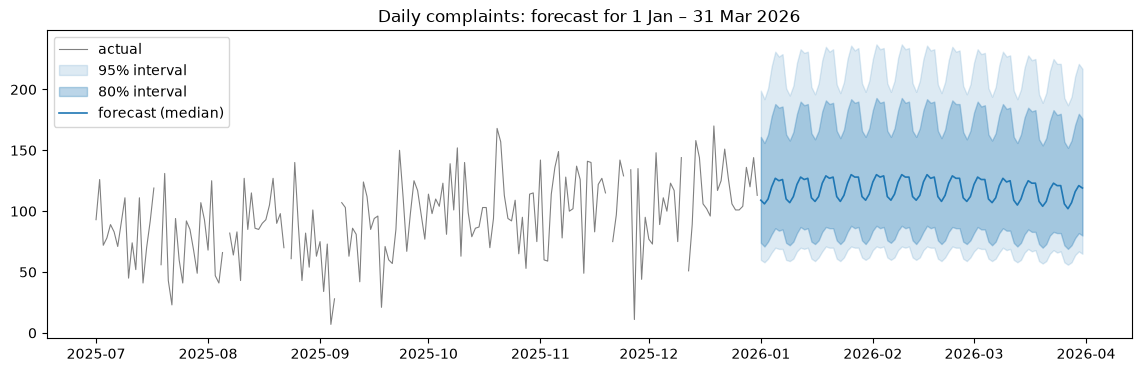

In [47]:
OUT = Path("../outputs")
OUT.mkdir(exist_ok=True)

forecast = make_dhr(K=2, recent_days=365)(y_all, H).rename(columns={"mean": "forecast"}).round().astype(int)
forecast.index.name = "date"
assert len(forecast) == 90 and forecast.index[0] == pd.Timestamp("2026-01-01") and forecast.index[-1] == pd.Timestamp("2026-03-31")
forecast.to_csv(OUT / "forecast_2026Q1.csv")

# Weekly totals of the daily forecasts, weeks starting Monday; 'days' flags the partial first and last weeks.
# No weekly intervals: daily interval bounds don't add up to a weekly interval
weekly = forecast["forecast"].resample("W-MON", label="left", closed="left").agg(["sum", "count"])
weekly.columns = ["total", "days"]
weekly.index.name = "week_starting"
weekly.to_csv(OUT / "weekly_totals_2026Q1.csv")

# Sanity check: the forecast level against the same season last year
q1_2025 = df.loc["2025-01-01":"2025-03-31", "complaints"].mean()
print(f"Mean daily forecast {forecast['forecast'].mean():.0f} vs Jan–Mar 2025 actual {q1_2025:.0f} "
      f"({100 * (forecast['forecast'].mean() / q1_2025 - 1):+.0f}%)")
print(weekly.to_string())

hist = df.loc["2025-07-01":, "complaints"]
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(hist.index, hist, lw=0.8, color="grey", label="actual")
ax.fill_between(forecast.index, forecast["lo95"], forecast["hi95"], color="C0", alpha=0.15, label="95% interval")
ax.fill_between(forecast.index, forecast["lo80"], forecast["hi80"], color="C0", alpha=0.3, label="80% interval")
ax.plot(forecast.index, forecast["forecast"], color="C0", lw=1.2, label="forecast (median)")
ax.set_title("Daily complaints: forecast for 1 Jan – 31 Mar 2026")
ax.legend(loc="upper left")
fig.savefig(OUT / "forecast_2026Q1.png", dpi=150, bbox_inches="tight")
plt.show()

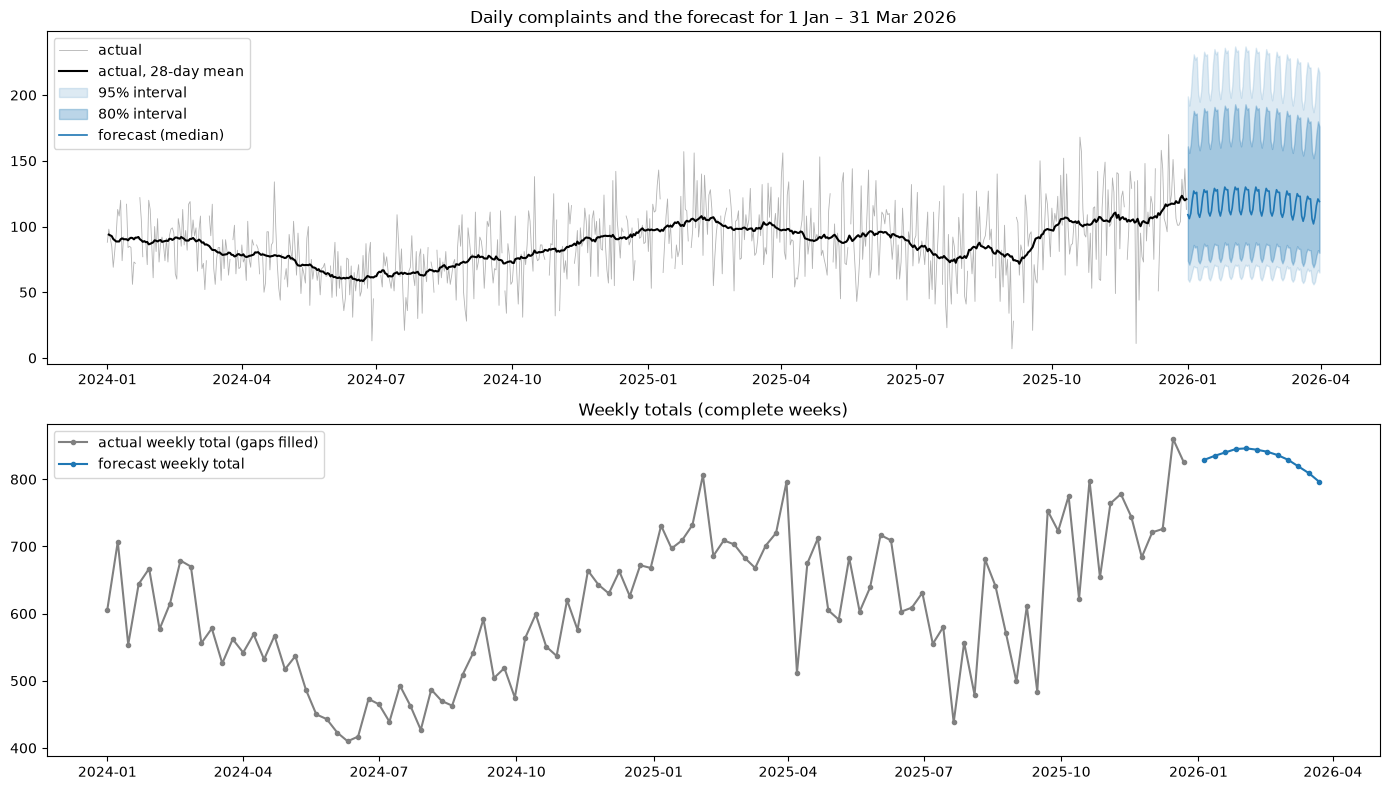

In [48]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8))

hist = df.loc["2024-01-01":, "complaints"]
ax1.plot(hist.index, hist, lw=0.6, color="grey", alpha=0.6, label="actual")
ax1.plot(hist.index, hist.rolling(28, center=True, min_periods=14).mean(), color="black", lw=1.5, label="actual, 28-day mean")
ax1.fill_between(forecast.index, forecast["lo95"], forecast["hi95"], color="C0", alpha=0.15, label="95% interval")
ax1.fill_between(forecast.index, forecast["lo80"], forecast["hi80"], color="C0", alpha=0.3, label="80% interval")
ax1.plot(forecast.index, forecast["forecast"], color="C0", lw=1.2, label="forecast (median)")
ax1.set_title("Daily complaints and the forecast for 1 Jan – 31 Mar 2026")
ax1.legend(loc="upper left")

# Weekly totals: the planning unit, far less noisy than single days. Complete weeks only, gaps filled
wk = y_all.loc["2024-01-01":].resample("W-MON", label="left", closed="left").agg(["sum", "count"])
wk_hist = wk.loc[wk["count"] == 7, "sum"]
wk_fc = weekly.loc[weekly["days"] == 7, "total"]
ax2.plot(wk_hist.index, wk_hist, color="grey", marker=".", label="actual weekly total (gaps filled)")
ax2.plot(wk_fc.index, wk_fc, color="C0", marker=".", label="forecast weekly total")
ax2.set_title("Weekly totals (complete weeks)")
ax2.legend(loc="upper left")

fig.tight_layout()
fig.savefig(OUT / "forecast_2026Q1.png", dpi=150, bbox_inches="tight")
plt.show()

**Checkpoint: final forecast.** Mean daily forecast of 118 complaints, +17% on Jan–Mar 2025 (101), in line with the model's 18% annual growth.

- **Shape:** weekly totals peak at about 845 in late January and early February and ease to about 800 by late March. The annual cycle turns down after its late-January peak, which outweighs three months of growth.
- **Why it looks smoother than the history:** day-to-day spikes are unpredictable noise (AR ≈ 0), so the forecast shows the typical day and the intervals carry the spread. Intervals are 29% wider than the model's raw ones (recent-spread factor 1.29), reflecting the noisier recent period.
- **Caveats:** the backtest under-forecast by about 5% in this same season, so the true level is more likely above the median than below it. 1 Jan is forecast as a normal Thursday. Weekly totals have no intervals, because daily bounds don't add up to weekly ones.

Forecast overview

Top: daily complaints since 2024 with a 28-day mean, and the 2026 forecast with 80% and 95% intervals. Bottom: weekly totals, the unit capacity planning uses, on complete weeks only. The forecast picks up from the late-2025 level (about 830 a week) and follows the same easing from February into March seen in both 2024 and 2025.

# BONUS: does a foundation model help?

Chronos-Bolt (small) is a pretrained time-series model used zero-shot: no fitting, it reads the history and outputs quantiles. Scored on the same four windows and metrics. Per the selection rule fixed before any results, it is reported as a comparison and does not replace the final model.

Two caveats: Chronos-Bolt was trained to output the 10th–90th percentiles, so its 95% interval is capped at its 80% bounds and 95% coverage isn't meaningful here; and 90 days is beyond its native 64-day horizon.

In [50]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")  # cosmetic notebook-widget warning at import
import torch
from chronos import BaseChronosPipeline

bolt = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small", device_map="cpu")

def chronos_bolt(train, h):
    """Zero-shot Chronos-Bolt: reads the cleaned history, returns quantiles as the forecast and intervals."""
    # Only the quantiles it was trained on; 95% bounds = 80% bounds by construction (see caveat above)
    q, _ = bolt.predict_quantiles(torch.tensor(train.to_numpy(), dtype=torch.float32), prediction_length=h, quantile_levels=[0.1, 0.5, 0.9])
    q = q[0].numpy()
    idx = pd.date_range(train.index[-1] + pd.Timedelta(days=1), periods=h, freq="D")
    return pd.DataFrame({"mean": q[:, 1], "lo80": q[:, 0], "hi80": q[:, 2], "lo95": q[:, 0], "hi95": q[:, 2]}, index=idx)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)  # the >64-day horizon caveat, stated above; would repeat per window
    cb = backtest(chronos_bolt, "Chronos-Bolt (zero-shot)")
print(cb.round(2).to_string())
print(pd.concat([dhr2r, cb]).groupby("model", sort=False).mean(numeric_only=True).round(2).to_string())

Loading weights: 100%|██████████| 143/143 [00:00<00:00, 2045.31it/s]


                      model       window    MAE  MASE  weekly_APE_%  bias_%  cover_80  cover_95  width_80_%
0  Chronos-Bolt (zero-shot)  W1 Jan 2025  23.06  1.66         13.99  -15.52      0.68      0.68       51.36
1  Chronos-Bolt (zero-shot)  W2 Apr 2025  20.46  1.35          9.59    1.27      0.82      0.82       72.56
2  Chronos-Bolt (zero-shot)  W3 Jul 2025  24.96  1.50         24.61   16.17      0.76      0.76       93.35
3  Chronos-Bolt (zero-shot)  W4 Oct 2025  24.35  1.39          8.70   -4.19      0.82      0.82       74.96
                                      MAE  MASE  weekly_APE_%  bias_%  cover_80  cover_95  width_80_%
model                                                                                                
DHR (K=2), recent-spread intervals  22.31  1.41         11.53   -5.95      0.75      0.90       66.50
Chronos-Bolt (zero-shot)            23.21  1.47         14.22   -0.57      0.77      0.77       73.06


**Checkpoint: bonus result.** Zero-shot Chronos-Bolt averages MASE 1.47, beating seasonal naive (1.76) with no fitting and coming within 0.06 of DHR (1.41). It wins W2 and ties W4, but loses W1, the same season as the real forecast (1.66 vs 1.37, bias −15.5%), much like DHR without annual terms: two years of history don't seem to be enough for it to pick up the annual cycle. Its near-zero average bias hides swings of −16% to +16%. DHR remains the final model. Next steps worth testing: fine-tuning Chronos on this series, or Chronos-2 with calendar features as known covariates.